# Exercise 2 - CNN vs MLP

CNN with three trainable layers: Conv(3->32) - Pool - Conv(32->64) - Pool - Linear. Same split, optimiser, learning rate, batch size and epochs as the MLP.

In [1]:
import os, time, copy, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

EPOCHS = 30          # training epochs
LR = 1e-3            # Adam learning rate
BATCH_SIZE = 128
NUM_WORKERS = 2
ROOT = "./data"
os.makedirs("figures", exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available()
                      else "mps" if torch.backends.mps.is_available() else "cpu")
print("Using device:", DEVICE)

def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

Using device: cuda


CIFAR-10 Dataset Preparation, Image Transformations, and DataLoader Configuration

In [2]:
CLASSES = ["aeroplane","automobile","bird","cat","deer","dog","frog","horse","ship","truck"]
MEAN, STD = (0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)

eval_tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

aug_tf = transforms.Compose([
    transforms.RandomAffine(degrees=10, translate=(0.1, 0.1)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

train_eval_full = datasets.CIFAR10(ROOT, train=True,  download=True,  transform=eval_tf)
train_aug_full  = datasets.CIFAR10(ROOT, train=True,  download=False, transform=aug_tf)
test_set        = datasets.CIFAR10(ROOT, train=False, download=True,  transform=eval_tf)

perm = torch.randperm(50000, generator=torch.Generator().manual_seed(42)).tolist()
train_idx, val_idx = perm[:45000], perm[45000:]
print(f"train={len(train_idx)}  val={len(val_idx)}  test={len(test_set)}")

def make_loaders(augment=False, seed=0):

    g = torch.Generator().manual_seed(seed)
    src = train_aug_full if augment else train_eval_full
    train_loader = DataLoader(Subset(src, train_idx), batch_size=BATCH_SIZE, shuffle=True,
                              num_workers=NUM_WORKERS, generator=g)
    clean_train = DataLoader(Subset(train_eval_full, train_idx), batch_size=512, num_workers=NUM_WORKERS)
    val_loader  = DataLoader(Subset(train_eval_full, val_idx),   batch_size=512, num_workers=NUM_WORKERS)
    test_loader = DataLoader(test_set, batch_size=512, num_workers=NUM_WORKERS)
    return train_loader, clean_train, val_loader, test_loader

100%|██████████| 170M/170M [27:14<00:00, 104kB/s]


train=45000  val=5000  test=10000


Model Training, Evaluation, and Performance Visualization Functions

In [3]:
def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

def run_epoch(model, loader, optimizer=None):
    train = optimizer is not None
    model.train(train)
    tot_loss = tot_correct = n = 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            out = model(x)
            loss = F.cross_entropy(out, y)
            if train:
                optimizer.zero_grad(); loss.backward(); optimizer.step()
            tot_loss += loss.item() * len(y)
            tot_correct += (out.argmax(1) == y).sum().item()
            n += len(y)
    return tot_loss / n, tot_correct / n

def train_model(model, loaders, epochs=EPOCHS, lr=LR, verbose=True):

    train_loader, clean_train, val_loader, test_loader = loaders
    model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = {k: [] for k in ["train_loss", "val_loss", "train_acc", "val_acc"]}
    best_val, best_state, best_epoch, t0 = -1, None, 0, time.time()
    for ep in range(1, epochs + 1):
        tl, ta = run_epoch(model, train_loader, opt)   # running stats in train mode
        vl, va = run_epoch(model, val_loader)
        for k, v in zip(hist, [tl, vl, ta, va]): hist[k].append(v)
        if va > best_val:
            best_val, best_epoch, best_state = va, ep, copy.deepcopy(model.state_dict())
        if verbose and (ep % 5 == 0 or ep == 1):
            print(f"ep {ep:02d} | train loss {tl:.3f} acc {ta:.3f} | val loss {vl:.3f} acc {va:.3f}")
    model.load_state_dict(best_state)
    ctl, cta = run_epoch(model, clean_train)    # train accuracy in eval mode on un-augmented data
    vl, va = run_epoch(model, val_loader)
    tel, tea = run_epoch(model, test_loader)
    res = dict(params=count_params(model), best_epoch=best_epoch, train_loss=ctl, train_acc=cta,
               val_loss=vl, val_acc=va, test_loss=tel, test_acc=tea, gap=cta - tea,
               final_epoch_train_loss=hist["train_loss"][-1], time_s=time.time() - t0)
    return hist, res

def plot_history(hist, title, fname=None):
    ep = range(1, len(hist["train_loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
    ax[0].plot(ep, hist["train_loss"], label="Training"); ax[0].plot(ep, hist["val_loss"], label="Validation")
    ax[0].set(title=f"{title}: loss", xlabel="Epoch", ylabel="Cross-entropy loss"); ax[0].legend(); ax[0].grid(alpha=.3)
    ax[1].plot(ep, hist["train_acc"], label="Training"); ax[1].plot(ep, hist["val_acc"], label="Validation")
    ax[1].set(title=f"{title}: accuracy", xlabel="Epoch", ylabel="Accuracy"); ax[1].legend(); ax[1].grid(alpha=.3)
    plt.tight_layout()
    if fname: plt.savefig(f"figures/{fname}.png", dpi=200)
    plt.show()

@torch.no_grad()
def confusion(model, loader):
    model.eval(); cm = np.zeros((10, 10), dtype=int)
    for x, y in loader:
        p = model(x.to(DEVICE)).argmax(1).cpu().numpy()
        for t, q in zip(y.numpy(), p): cm[t, q] += 1
    return cm

def plot_confusion(cm, title, fname=None):
    plt.figure(figsize=(6.2, 5.4)); plt.imshow(cm, cmap="Blues"); plt.colorbar()
    plt.xticks(range(10), CLASSES, rotation=60, ha="right"); plt.yticks(range(10), CLASSES)
    for i in range(10):
        for j in range(10):
            plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=6,
                     color="white" if cm[i, j] > cm.max() / 2 else "black")
    plt.title(title); plt.xlabel("Predicted"); plt.ylabel("True"); plt.tight_layout()
    if fname: plt.savefig(f"figures/{fname}.png", dpi=200)
    plt.show()

Neural Network Architecture Definitions

In [4]:
class MLP(nn.Module):

    def __init__(self, h1=512, h2=256):
        super().__init__()
        self.net = nn.Sequential(nn.Flatten(), nn.Linear(3 * 32 * 32, h1), nn.ReLU(),
                                 nn.Linear(h1, h2), nn.ReLU(), nn.Linear(h2, 10))
    def forward(self, x): return self.net(x)

def build_cnn(channels, dropout=0.0, max_pools=3, n_classes=10):

    layers, c = [], 3
    for i, ch in enumerate(channels):
        layers += [nn.Conv2d(c, ch, 3, padding=1), nn.ReLU()]
        if i < max_pools: layers.append(nn.MaxPool2d(2))
        c = ch
    layers.append(nn.Flatten())
    with torch.no_grad():
        d = nn.Sequential(*layers)(torch.zeros(1, 3, 32, 32)).shape[1]
    if dropout > 0: layers.append(nn.Dropout(dropout))
    layers.append(nn.Linear(d, n_classes))
    return nn.Sequential(*layers)

Baseline Model Training (MLP and CNN)

In [5]:
set_seed(0); loaders = make_loaders(augment=False, seed=0)
mlp = MLP();                         hist_mlp, res_mlp = train_model(mlp, loaders, verbose=False)
set_seed(0); loaders = make_loaders(augment=False, seed=0)
cnn = build_cnn([32, 64]);           hist_cnn, res_cnn = train_model(cnn, loaders, verbose=False)
print(cnn)

Sequential(
  (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Flatten(start_dim=1, end_dim=-1)
  (7): Linear(in_features=4096, out_features=10, bias=True)
)


## Comparison table (accuracy, loss, parameters)

In [6]:
tbl = pd.DataFrame([res_mlp, res_cnn], index=["MLP", "CNN"])
cols = ["params", "train_acc", "val_acc", "test_acc", "train_loss", "val_loss", "best_epoch"]
display(tbl[cols].round(4)); tbl.round(4).to_csv("ex2_results.csv")

,params,train_acc,val_acc,test_acc,train_loss,val_loss,best_epoch
MLP,1707274,0.8110,0.5264,0.5215,0.5406,1.7783,13
CNN,60362,0.8625,0.7156,0.7190,0.4204,0.8824,11


## Training/validation loss - MLP vs CNN

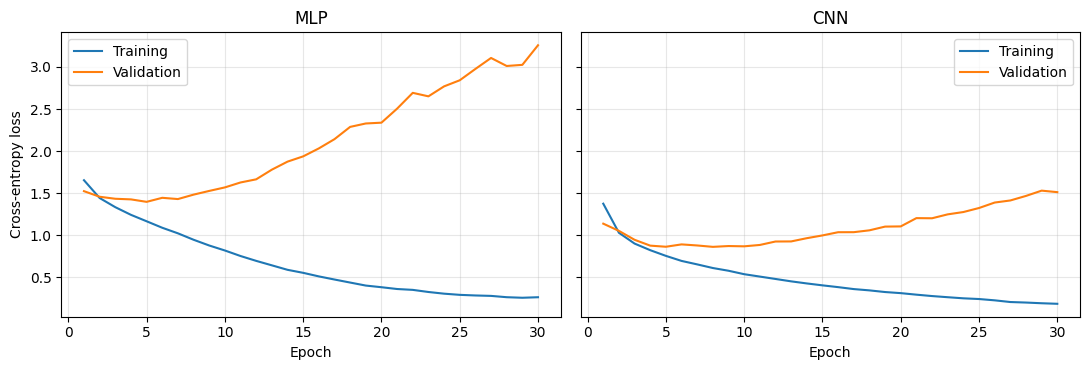

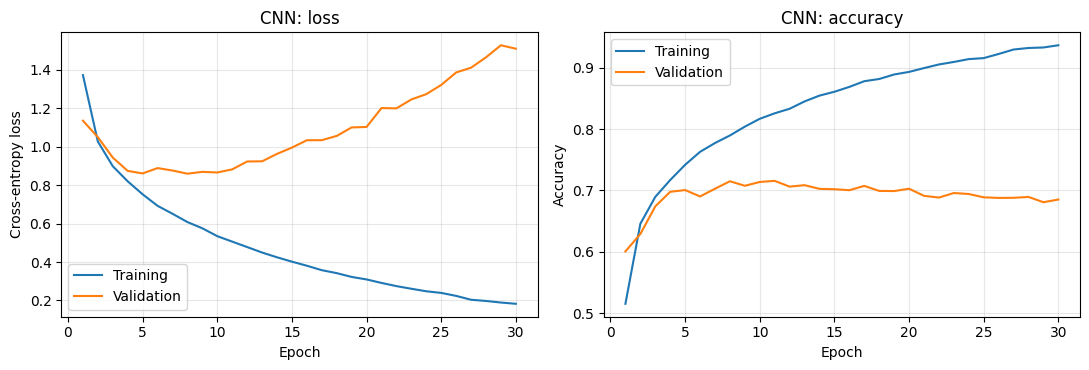

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for a, (h, n) in zip(ax, [(hist_mlp, "MLP"), (hist_cnn, "CNN")]):
    e = range(1, EPOCHS + 1)
    a.plot(e, h["train_loss"], label="Training"); a.plot(e, h["val_loss"], label="Validation")
    a.set(title=n, xlabel="Epoch"); a.grid(alpha=.3); a.legend()
ax[0].set_ylabel("Cross-entropy loss"); plt.tight_layout(); plt.savefig("figures/ex2_loss_mlp_vs_cnn.png", dpi=200); plt.show()
plot_history(hist_cnn, "CNN", "ex2_cnn_curves")

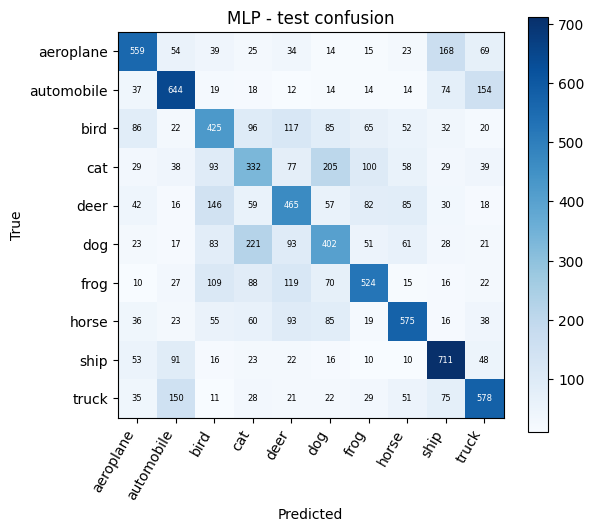

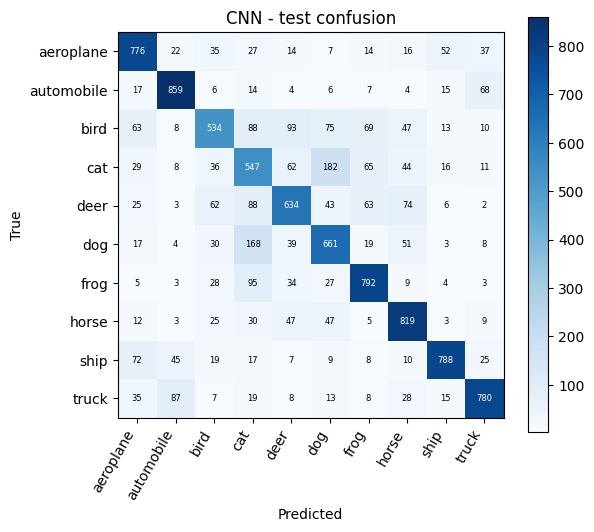

In [8]:
plot_confusion(confusion(mlp, loaders[3]), "MLP - test confusion", "ex2_conf_mlp")
plot_confusion(confusion(cnn, loaders[3]), "CNN - test confusion", "ex2_conf_cnn")

## Learned first-layer convolution filters

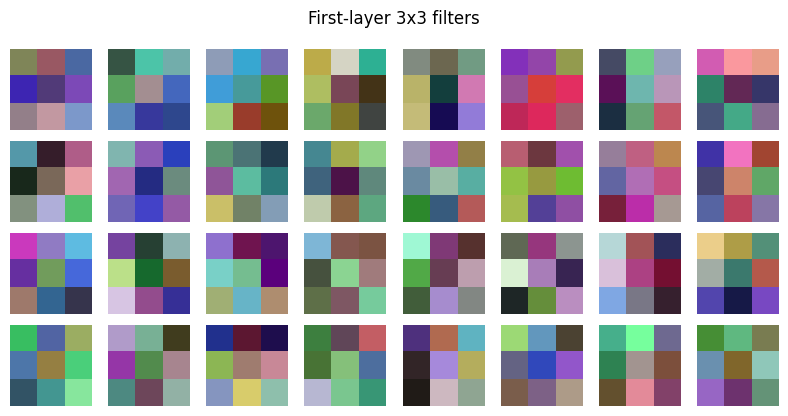

In [9]:
w = cnn[0].weight.detach().cpu().clone()          # (32, 3, 3, 3)
w = (w - w.min()) / (w.max() - w.min())
fig, ax = plt.subplots(4, 8, figsize=(8, 4.2))
for i, a in enumerate(ax.flat):
    a.imshow(w[i].permute(1, 2, 0).numpy(), interpolation="nearest"); a.axis("off")
plt.suptitle("First-layer 3x3 filters"); plt.tight_layout(); plt.savefig("figures/ex2_filters.png", dpi=200); plt.show()

### Notes for the report
- Parameters: CNN uses far fewer parameters than the MLP yet should achieve higher accuracy - explain via local receptive fields, weight sharing and translation equivariance, pooling invariance.
- Compare overfitting behaviour (loss curves, train/val gap).
- Link filters to edge/colour detectors.